# 07 - Transfer learning: from white wines to red wines
Wine Quality dataset, regression of the quality score

After removing duplicates there are 3,961 white wines but only 1,359 red wines. In the ML report
one model with both types worked as well as one model per type, and the clusters separated red
from white wines. So the two types are different, but maybe what the network learns about white
wines is still useful for red wines.

Idea (the same as the transfer learning notebook seen in class, where a ResNet trained on ImageNet
is reused for CIFAR-10):

1. **Pre-train** a network on the white wines only.
2. **Fine-tune** it with a small number $n$ of red wines.
3. Compare with a network trained **from scratch** with the same $n$ red wines.

We try $n$ = 25, 50, 100, 200, 400, 800 and all the red training wines, and we evaluate on red
wines that were never used (5 folds over the red wines). We will see that the way the inputs are
standardised is very important here. The inputs are the 11 physicochemical
variables (`is_red` is not used, it would be constant).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, f1_score, accuracy_score

from utils import *

set_style()
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

In [2]:
from sklearn.ensemble import RandomForestRegressor

wine = load_wine()
white = wine[wine.wine_type == "white"]
red = wine[wine.wine_type == "red"]
Xw, yw = white[PHYSCHEM].to_numpy(), white["quality"].to_numpy().astype(float)
Xr, yr = red[PHYSCHEM].to_numpy(), red["quality"].to_numpy().astype(float)
print("White wines:", Xw.shape, "  Red wines:", Xr.shape)

HIDDEN, DROPOUT = (64, 32), 0.1
mse = nn.MSELoss()
def reg_loss(out, yb):
    return mse(out.squeeze(1), yb)

White wines: (3961, 11)   Red wines: (1359, 11)


## 1. Pre-training on white wines

In [3]:
tr, val = train_test_split(np.arange(len(Xw)), test_size=0.15, random_state=SEED)
w_scaler = StandardScaler().fit(Xw[tr])
w_mean, w_std = yw[tr].mean(), yw[tr].std()

torch.manual_seed(SEED)
pretrained = MLP(Xw.shape[1], HIDDEN, 1, DROPOUT)
hist = train_model(pretrained, to_tensor(w_scaler.transform(Xw[tr])), (to_tensor((yw[tr] - w_mean) / w_std),),
                   to_tensor(w_scaler.transform(Xw[val])), (to_tensor((yw[val] - w_mean) / w_std),), reg_loss)

def predict(model, Xs, mean, std):
    model.eval()
    with torch.no_grad():
        return model(to_tensor(Xs)).squeeze(1).numpy() * std + mean

p = predict(pretrained, w_scaler.transform(Xw[val]), w_mean, w_std)
print("Pre-trained network, RMSE on white validation wines: %.3f (best epoch %d)" % (rmse(yw[val], p), hist["best_epoch"]))

Pre-trained network, RMSE on white validation wines: 0.722 (best epoch 45)


## 2. First try: the white model directly on red wines

If we use the white network on red wines, with the white scaler, the error is huge (much worse than
predicting always the mean). The reason is that the red wines are far away from the white wines
in the input space: when they are standardised with the white statistics, some variables are
several standard deviations away from zero, so the network receives inputs it has never seen.

White model on ALL red wines (white scaler): RMSE 1.627
Predicting the mean of the red wines        : RMSE 0.823
Figure saved -> ../results/figures/tl_domain_shift.png


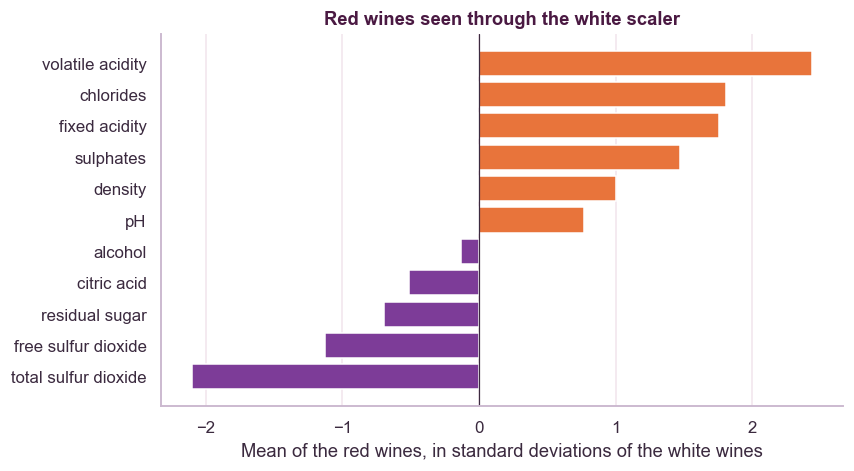

In [4]:
p = predict(pretrained, w_scaler.transform(Xr), w_mean, w_std)
print("White model on ALL red wines (white scaler): RMSE %.3f" % rmse(yr, p))
print("Predicting the mean of the red wines        : RMSE %.3f" % yr.std())

shift = pd.Series(w_scaler.transform(Xr).mean(axis=0), index=PHYSCHEM).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(shift.index, shift.values, color=[PURPLE if v < 0 else ORANGE for v in shift.values], edgecolor="white")
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Mean of the red wines, in standard deviations of the white wines")
ax.set_title("Red wines seen through the white scaler")
ax.grid(axis="y", visible=False)
save(fig, "tl_domain_shift.png")
plt.show()

A simple solution is to **standardise each wine type with its own statistics** (inputs and target).
For the red wines, the means and standard deviations are computed only with the $n$ red training
wines. In this way "a high value of sulphates" means "high for a red wine", and the white network
can be reused.

## 3. Strategies

* **From scratch:** new network, trained only with the $n$ red wines.
* **White model, only re-scaled:** the pre-trained network without any training on red wines
  (the $n$ red wines are only used to compute the means and standard deviations).
* **Fine-tune head only:** the shared layers are frozen and only the last layer is trained
  (learning rate 0.001), like in the transfer learning notebook of class.
* **Fine-tune all layers:** all the weights are trained starting from the pre-trained ones, with
  a smaller learning rate (0.0003) so that the network does not forget too fast what it learned.
* **Fine-tune all layers, white scaler:** the same, but keeping the white scaler (the naive way).
* **Random forest from scratch:** the best ML model, trained with the same $n$ red wines, as a reference.

For the networks, 20% of the $n$ red wines (at least 5) are used as validation set for early stopping.

In [5]:
def fine_tune(Xs_tr, ys_tr, Xs_val, ys_val, head_only):
    # Xs and ys are already standardised
    model = copy.deepcopy(pretrained)
    if head_only:
        for p in model.body.parameters():
            p.requires_grad = False
        params, lr = model.head.parameters(), 1e-3
    else:
        params, lr = model.parameters(), 3e-4
    train_model(model, to_tensor(Xs_tr), (to_tensor(ys_tr),), to_tensor(Xs_val), (to_tensor(ys_val),),
                reg_loss, lr=lr, params=params)
    return model

## 4. Experiment

In [6]:
SIZES = [25, 50, 100, 200, 400, 800, "all"]
outer = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []

for fold, (pool_idx, test_idx) in enumerate(outer.split(Xr), start=1):
    rng = np.random.default_rng(SEED + fold)
    order = rng.permutation(pool_idx)            # the smaller samples are inside the bigger ones
    X_te, y_te = Xr[test_idx], yr[test_idx]

    for size in SIZES:
        n = len(order) if size == "all" else size
        sample = order[:n]
        n_val = max(5, int(round(0.2 * n)))
        s_val, s_tr = sample[:n_val], sample[n_val:]
        res = {"fold": fold, "n": n}

        # red statistics, computed only with the red training wines
        r_scaler = StandardScaler().fit(Xr[s_tr])
        r_mean, r_std = yr[s_tr].mean(), yr[s_tr].std()
        Xs_tr, Xs_val, Xs_te = (r_scaler.transform(Xr[i]) for i in (s_tr, s_val, test_idx))
        ys_tr, ys_val = (yr[s_tr] - r_mean) / r_std, (yr[s_val] - r_mean) / r_std

        torch.manual_seed(SEED)
        scratch = MLP(Xr.shape[1], HIDDEN, 1, DROPOUT)
        train_model(scratch, to_tensor(Xs_tr), (to_tensor(ys_tr),), to_tensor(Xs_val), (to_tensor(ys_val),), reg_loss)
        res["From scratch"] = rmse(y_te, predict(scratch, Xs_te, r_mean, r_std))

        res["White model, only re-scaled"] = rmse(y_te, predict(pretrained, Xs_te, r_mean, r_std))

        for name, head_only in [("Fine-tune head only", True), ("Fine-tune all layers", False)]:
            torch.manual_seed(SEED)
            ft = fine_tune(Xs_tr, ys_tr, Xs_val, ys_val, head_only)
            res[name] = rmse(y_te, predict(ft, Xs_te, r_mean, r_std))

        # naive version: white scaler and white target statistics
        torch.manual_seed(SEED)
        ft = fine_tune(w_scaler.transform(Xr[s_tr]), (yr[s_tr] - w_mean) / w_std,
                       w_scaler.transform(Xr[s_val]), (yr[s_val] - w_mean) / w_std, head_only=False)
        res["Fine-tune all layers, white scaler"] = rmse(y_te, predict(ft, w_scaler.transform(X_te), w_mean, w_std))

        rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Xr[sample], yr[sample])
        res["Random forest from scratch"] = rmse(y_te, rf.predict(X_te))
        rows.append(res)
    print(f"fold {fold} done")

tl = pd.DataFrame(rows)
tl["n"] = tl.groupby(tl.index % len(SIZES))["n"].transform("min")   # 'all' is ~1087 wines
tl.to_csv(RES_DIR / "transfer_learning_folds.csv", index=False)
STRATS = ["From scratch", "White model, only re-scaled", "Fine-tune head only", "Fine-tune all layers",
          "Fine-tune all layers, white scaler", "Random forest from scratch"]
tl_summary = tl.groupby("n")[STRATS].mean()
tl_summary.to_csv(RES_DIR / "transfer_learning_summary.csv")
tl_summary.round(3)

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


,From scratch,"White model, only re-scaled",Fine-tune head only,Fine-tune all layers,"Fine-tune all layers, white scaler",Random forest from scratch
n,,,,,,
25,0.816,0.776,0.757,0.751,0.819,0.759
50,0.762,0.766,0.749,0.727,0.812,0.721
100,0.732,0.757,0.739,0.728,0.770,0.706
200,0.697,0.755,0.717,0.693,0.704,0.677
400,0.663,0.759,0.688,0.674,0.664,0.652
800,0.661,0.761,0.680,0.659,0.654,0.652
1087,0.651,0.759,0.680,0.654,0.649,0.646


## 5. Learning curve

Figure saved -> ../results/figures/tl_learning_curve.png


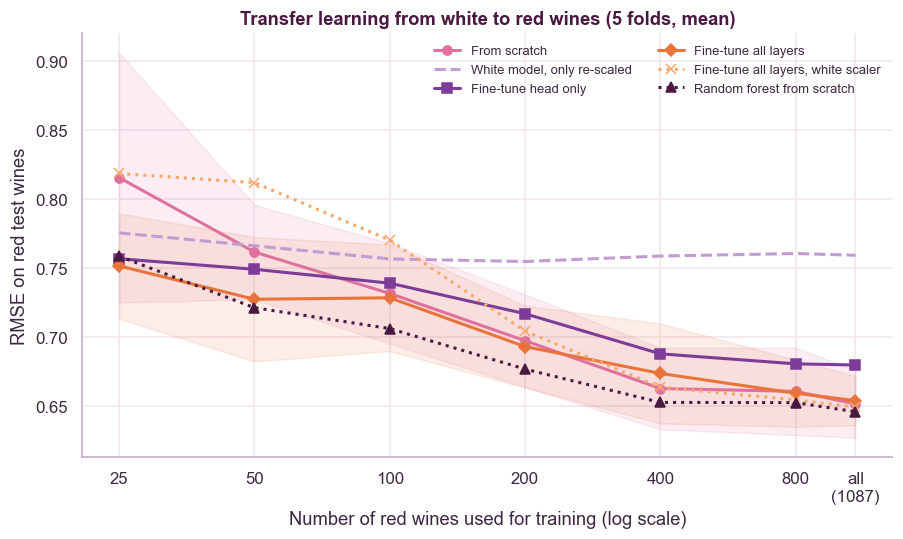

In [7]:
style = {"From scratch": (PINK, "-", "o"),
         "White model, only re-scaled": (LILAC, "--", None),
         "Fine-tune head only": (PURPLE, "-", "s"),
         "Fine-tune all layers": (ORANGE, "-", "D"),
         "Fine-tune all layers, white scaler": (APRICOT, ":", "x"),
         "Random forest from scratch": (PLUM, ":", "^")}
fig, ax = plt.subplots(figsize=(9.5, 5))
ns = tl_summary.index.to_numpy()
for name, (col, ls, mk) in style.items():
    ax.plot(ns, tl_summary[name], color=col, ls=ls, marker=mk, lw=2, label=name)
    if name in ("From scratch", "Fine-tune all layers"):
        sd = tl.groupby("n")[name].std()
        ax.fill_between(ns, tl_summary[name] - sd, tl_summary[name] + sd, color=col, alpha=0.12)
ax.set_xscale("log")
ax.set_xticks(ns)
ax.set_xticklabels([str(n) for n in ns[:-1]] + [f"all\n({ns[-1]})"])
ax.minorticks_off()
ax.set_xlabel("Number of red wines used for training (log scale)")
ax.set_ylabel("RMSE on red test wines")
ax.set_title("Transfer learning from white to red wines (5 folds, mean)")
ax.legend(fontsize=8.5, ncol=2)
save(fig, "tl_learning_curve.png")
plt.show()

## Summary

* Used naively (white scaler), the white network is useless for red wines, and fine-tuning it
  is never better than starting from scratch.
* If each wine type is standardised with its own statistics, the white network already gives a
  reasonable error on red wines without any training, and fine-tuning all the layers is better than
  training from scratch when there are few red wines (25 - 100).
* With a few hundred red wines the advantage disappears (or becomes negative), because there is
  enough data to learn the red wines from scratch.
* With only 25 red wines the fine-tuned network is the best model, slightly better than the random
  forest. From 50 red wines on, the random forest is again the best model.